In [16]:
import os 
#os.environ["JAX_PLATFORM_NAME"] = 'cpu'
%load_ext autoreload
%autoreload 2
import jax.numpy as jnp
import numpy as onp

import jax
import numpy as onp
from functools import partial
jax.config.update("jax_enable_x64", True)

from typing import Callable
import pyvista as pv
from jax_sn.domain.geometric_domain import TopologicalSortedAngle
from jax_sn.source import Source
from typing import List
onp.set_printoptions(linewidth = 200)

from jax_sn.domain.domain_generation import create_cartesian_setup
from jax_sn.solution_domain import BasixLagrangianSimplex, SolutionDomain
from jax_sn.domain import CrossSectionData, Domain

from jax_sn.operators.mass_operator import MassOperator
from jax_sn.operators.transport_operator import TransportOperatorBatched

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
def analytical_solution(x, sigma, q, x_max, angle):
    if angle[0] > 0:
        return q/sigma * (1.0 - jnp.exp(-sigma * x / angle[0]))
    elif angle[0] < 0:
        return (q/sigma) * (1.0 - jnp.exp(-sigma * (x_max - x) / jnp.abs(angle[0])))
    else:
        return q/sigma

def compute_L2_error(solution : jnp.ndarray, analytical_solution_f : Callable, solution_domain : SolutionDomain, quad_order : int) -> float:
    quad_points, quad_weights = solution_domain.element.volume_quadrature_order(quad_order)    
    def _squared_error(elem_idx : int) -> float:
        elem_tot = jnp.full(quad_points.shape[0], elem_idx, dtype=int)
        real_coords = solution_domain.element.real_coordinates(quad_points, elem_tot, solution_domain.domain, solution_domain.precomputed_geometric_data)
        analytical_values = analytical_solution_f(real_coords).flatten()
        numerical_values  = solution_domain.element.interpolate_from_local_coordinate(quad_points, elem_tot, solution)

        squared_error    = jnp.sum(quad_weights * (numerical_values - analytical_values)**2 * solution_domain.precomputed_geometric_data.vol_jacobians_det[elem_idx])
        return squared_error
    
    L2 = jnp.sqrt(jnp.sum(jax.vmap(_squared_error)(jnp.arange(solution_domain.domain.n_elements))))
    return L2

In [9]:
def setup_1d_slab(sigma: float, q: float, degree: int, n_cells: int, angle : jnp.ndarray):
    xs_0   = CrossSectionData.constant(sigma, 1, 1)
    verts, conn, cross_sections, sources = create_cartesian_setup(1, [[(1.0, n_cells)]], cross_sections_regions=[xs_0], source_regions=[q], inhomogeneity_direction=0)
    element_type                         = BasixLagrangianSimplex(degree, 1)
    domain                               = Domain.from_mesh_and_cross_sections((verts, conn), element_type.face_template, cross_sections)    

    solution_domain                      = SolutionDomain.from_element_and_domain(element_type, domain)
    
    source_mapped                        = Source(jnp.repeat(sources, element_type.n_basis, axis=-1).reshape(-1, element_type.n_basis))
    buffer_sweep                         = jnp.zeros((domain.n_elements, element_type.n_basis))
    toposort                             = TopologicalSortedAngle.from_domain_angle(domain, angle)
    return solution_domain, source_mapped, buffer_sweep, toposort


In [10]:
angle_non_norm = jnp.array([1.0, 0.5,0.0])
angle_norm     = angle_non_norm / jnp.linalg.norm(angle_non_norm)
sigma = 5.0
q     = 3.0
xmax = 1.0

analytical_solution_1D_slab = partial(analytical_solution, sigma=sigma, q=q, x_max=xmax, angle=angle_norm)

In [11]:
deg = 1
n_cells = 10
sol_domain, source, buffer, toposort = setup_1d_slab(sigma = sigma, q = q, degree = deg, n_cells = n_cells, angle = angle_norm)

In [17]:
mass_operator = MassOperator.from_fem_matrices_and_precomputed_geometric_data(sol_domain.fem_matrices, sol_domain.precomputed_geometric_data)
transport_operator = TransportOperatorBatched.from_solution_domain_data_and_toposort(sol_domain.solution_domain_data, toposort, batch_size = 10)

In [18]:
solution = transport_operator.inv(mass_operator(source.source_values),0 )

Text(0.5, 1.0, '1D slab single angle solution')

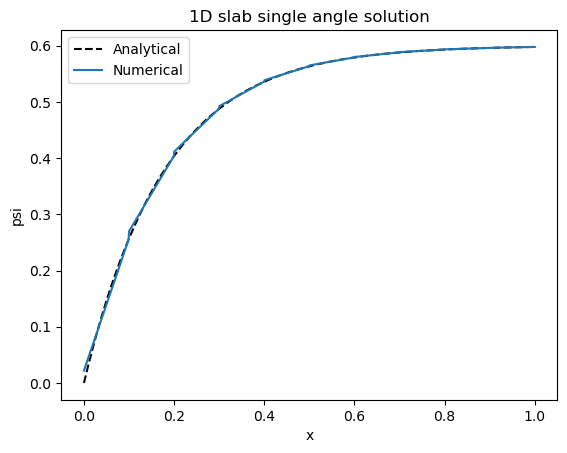

In [19]:
import matplotlib.pyplot as plt
x_vals = onp.linspace(0, 1.0, 1000)[:, None]
plt.plot(x_vals, analytical_solution_1D_slab(x_vals), label="Analytical", color='black', linestyle = 'dashed')
plt.plot(x_vals, sol_domain.interpolate(x_vals, solution), label="Numerical", linestyle='solid'); plt.xlabel("x"); plt.ylabel("psi"); plt.legend(); plt.title("1D slab single angle solution")


In [22]:
def convergence_study(deg : int, n_cells_list : List[int]):
    L2_errors = []
    for n_cells in n_cells_list:
        sol_domain, source, buffer, toposort = setup_1d_slab(sigma = sigma, q = q, degree = deg, n_cells = n_cells, angle = angle_norm)
        mass_operator = MassOperator.from_fem_matrices_and_precomputed_geometric_data(sol_domain.fem_matrices, sol_domain.precomputed_geometric_data)
        transport_operator = TransportOperatorBatched.from_solution_domain_data_and_toposort(sol_domain.solution_domain_data, toposort, batch_size = 10)
        solution = transport_operator.inv(mass_operator(source.source_values),0 )
        L2_error = compute_L2_error(solution, analytical_solution_1D_slab, sol_domain, quad_order=8*(deg+1))
        L2_errors.append(L2_error)
        print(f"Degree {deg}, Cells {n_cells}, L2 error: {L2_error}")
    return L2_errors


In [23]:
n_x = jnp.unique(jnp.logspace(jnp.log10(5), jnp.log10(80), num=10).astype(int))

print(n_x)

[ 4  6  9 12 17 23 31 43 58 79]


In [24]:
L2errs = [] 
for deg in [1,2,3]:
    L2err = convergence_study(deg=deg, n_cells_list=n_x)
    L2errs.append(L2err)

Degree 1, Cells 4, L2 error: 0.015620715722499932
Degree 1, Cells 6, L2 error: 0.007811787429574257
Degree 1, Cells 9, L2 error: 0.003731346212429295
Degree 1, Cells 12, L2 error: 0.0021703268626683133
Degree 1, Cells 17, L2 error: 0.0011120182049669473
Degree 1, Cells 23, L2 error: 0.0006177064365343381
Degree 1, Cells 31, L2 error: 0.0003440445049497624
Degree 1, Cells 43, L2 error: 0.00018045827577452064
Degree 1, Cells 58, L2 error: 9.9782641615784e-05
Degree 1, Cells 79, L2 error: 5.4026128564290826e-05
Degree 2, Cells 4, L2 error: 0.0018624828129804182
Degree 2, Cells 6, L2 error: 0.0006128582681578326
Degree 2, Cells 9, L2 error: 0.00019261536835275058
Degree 2, Cells 12, L2 error: 8.337009166874843e-05
Degree 2, Cells 17, L2 error: 2.9925285377770472e-05
Degree 2, Cells 23, L2 error: 1.2224712721636948e-05
Degree 2, Cells 31, L2 error: 5.03240021484516e-06
Degree 2, Cells 43, L2 error: 1.8969763773859853e-06
Degree 2, Cells 58, L2 error: 7.759779786821144e-07
Degree 2, Cells 79

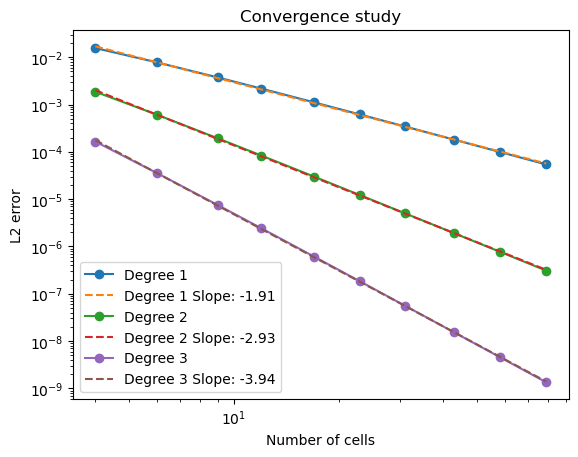

In [25]:
import matplotlib.pyplot as plt

for deg, L2err in zip([1,2,3], L2errs):
    plt.loglog(n_x, L2err, marker='o', label=f"Degree {deg}")
    # now fitting a line to the loglog data
    coeffs = jnp.polyfit(jnp.log10(n_x), jnp.log10(jnp.array(L2err)), 1) 
    plt.loglog(n_x, 10**coeffs[1] * n_x**coeffs[0], linestyle='dashed', label=f"Degree {deg} Slope: {coeffs[0]:.2f}")
plt.xlabel("Number of cells")
plt.ylabel("L2 error")
plt.title(f"Convergence study") 
plt.legend()

In [27]:
def setup_3d_slab(sigma: float, q: float, degree: int, n_cells: int, angle : jnp.ndarray):
    xs_0   = CrossSectionData.constant(sigma, 1, 1)
    verts, conn, cross_sections, sources = create_cartesian_setup(3, [[(1.0, n_cells)], [(1.0, n_cells)], [(1.0,n_cells)]], cross_sections_regions=[xs_0], source_regions=[q], inhomogeneity_direction=0)
    element_type                         = BasixLagrangianSimplex(degree, 3)
    domain                               = Domain.from_mesh_and_cross_sections((verts, conn), element_type.face_template, cross_sections)    

    solution_domain                      = SolutionDomain.from_element_and_domain(element_type, domain)
    
    source_mapped                        = Source(jnp.repeat(sources, element_type.n_basis, axis=-1).reshape(-1, element_type.n_basis))
    
    buffer_sweep                         = jnp.zeros((domain.n_elements, element_type.n_basis))
    toposort                             = TopologicalSortedAngle.from_domain_angle(domain, angle)
    return solution_domain, source_mapped, buffer_sweep, toposort


angle_non_norm = jnp.array([1.0, 0.5,0.0])
angle_norm     = angle_non_norm / jnp.linalg.norm(angle_non_norm)
sigma = 5.0
q     = 3.0
xmax  = 1.0




In [30]:
sol_domain, source_map, buffer, toposort = setup_3d_slab(sigma, q, 3, 20, angle_norm)
mass_op_3d = MassOperator.from_fem_matrices_and_precomputed_geometric_data(sol_domain.fem_matrices, sol_domain.precomputed_geometric_data)
transport_op_3d = TransportOperatorBatched.from_solution_domain_data_and_toposort(sol_domain.solution_domain_data, toposort, batch_size = 100)

result = transport_op_3d.inv(mass_op_3d(source_map.source_values),0 )

In [31]:
x_vals = jnp.linspace(0, 1.0, 1000)[:, None]
y_vals = jnp.ones_like(x_vals) * 0.2
z_vals = jnp.ones_like(x_vals) * 0.2
points = jnp.hstack([x_vals, y_vals, z_vals])
points.shape

(1000, 3)

In [32]:
print("Available same-level parallelism : ", jnp.min(jnp.bincount(toposort.levels)))

Available same-level parallelism :  400


In [33]:
pvalues_points = sol_domain.interpolate(points, result)

In [34]:
def compute_psi_box(points, a, omega, sigma, q):
    import numpy as np
    # points: (...,3) array of (x,y,z)
    # omega: (mu,eta,xi) array-like
    mu,eta,xi = np.asarray(omega)
    x = points[...,0]; y = points[...,1]; z = points[...,2]
    inf = np.inf

    # compute t_x, t_y, t_z with safe handling for zero components
    t_x = np.where(mu > 0, x/mu, np.where(mu < 0, (a - x)/(-mu), inf))
    t_y = np.where(eta> 0, y/eta, np.where(eta < 0, (a - y)/(-eta), inf))
    t_z = np.where(xi > 0, z/xi, np.where(xi < 0, (a - z)/(-xi), inf))

    s = np.minimum(np.minimum(t_x, t_y), t_z)

    if sigma == 0.0:
        psi = q * s
    else:
        psi = (q / sigma) * (1.0 - np.exp(-sigma * s))
    return psi


analytical = compute_psi_box(points, 1.0, angle_norm, sigma, q)

Text(0.5, 1.0, '3D slab single angle solution along x-axis')

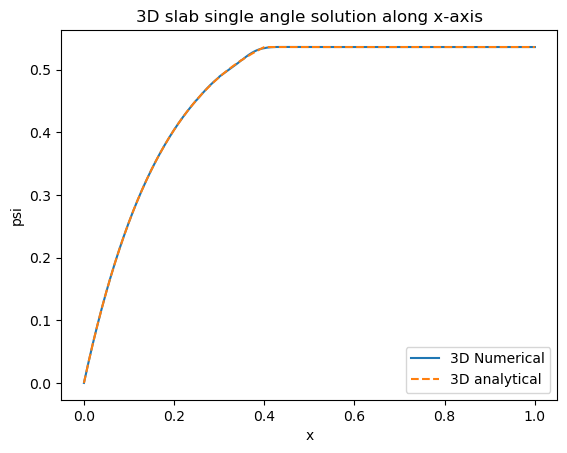

In [35]:
import matplotlib.pyplot as plt
plt.plot(x_vals, pvalues_points, label="3D Numerical", linestyle='solid')
plt.plot(x_vals, analytical, label="3D analytical", linestyle ="dashed"); plt.xlabel("x"); plt.ylabel("psi"); plt.legend(); plt.title("3D slab single angle solution along x-axis")